<a href="https://colab.research.google.com/github/Rikza-Aidil/simuteh-2330511084/blob/main/B3_histogram.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
from google.colab import drive
import os
import sys

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Arahkan direktori kerja ke folder 'notebook' Anda
os.chdir('/content/drive/MyDrive/Computer Vision/simuteh-2330511084/notebook')

# 3. Masukkan folder 'src' ke path agar modul utils_cv dapat diimpor
src_path = '/content/drive/MyDrive/Computer Vision/simuteh-2330511084/src'
if src_path not in sys.path:
    sys.path.append(src_path)

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("Lingkungan Bagian 3 siap digunakan!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Lingkungan Bagian 3 siap digunakan!


File: teh_041.png  | Statistik: {'rerata': 165.3, 'simpangan_baku': 38.4, 'min': 51, 'maks': 222, 'persen_gelap': 0.0, 'persen_terang': 0.5}
File: teh_042.png  | Statistik: {'rerata': 117.8, 'simpangan_baku': 34.1, 'min': 19, 'maks': 159, 'persen_gelap': 5.0, 'persen_terang': 0.0}
File: teh_043.png  | Statistik: {'rerata': 214.1, 'simpangan_baku': 25.7, 'min': 128, 'maks': 255, 'persen_gelap': 0.0, 'persen_terang': 75.7}
File: teh_044.png  | Statistik: {'rerata': 153.6, 'simpangan_baku': 14.1, 'min': 108, 'maks': 186, 'persen_gelap': 0.0, 'persen_terang': 0.0}
File: teh_045.png  | Statistik: {'rerata': 124.2, 'simpangan_baku': 52.4, 'min': 33, 'maks': 239, 'persen_gelap': 0.6, 'persen_terang': 10.4}


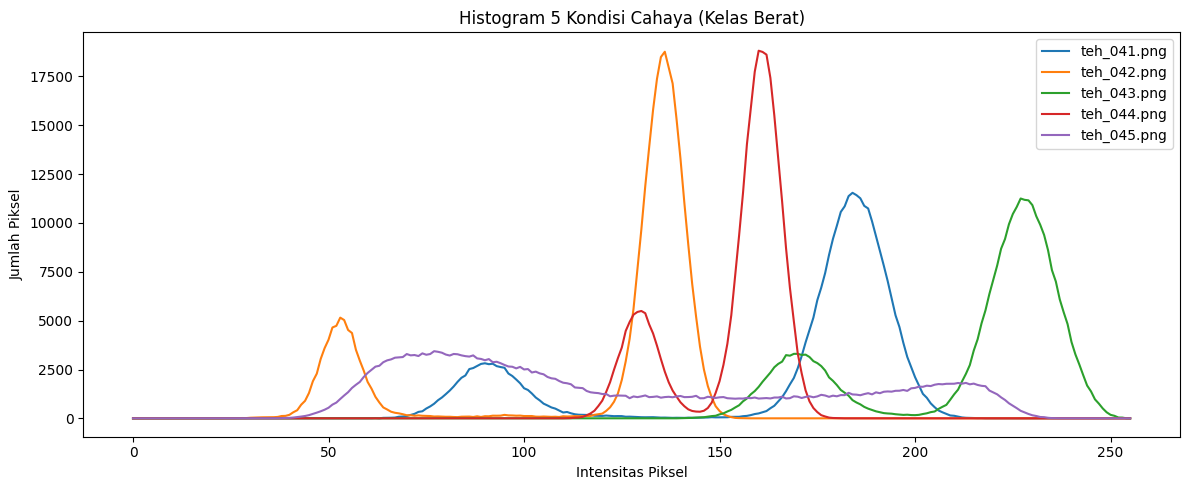

In [14]:
from utils_cv import baca, tampil, kontras_bercak, statistik
# 5 kondisi cahaya pada kelas berat
kondisi_files = ["teh_041.png", "teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png"]

plt.figure(figsize=(12, 5))
for nama in kondisi_files:
    img = baca(f"../data/sintetis/citra/{nama}")
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Cetak statistik mutu citra
    print(f"File: {nama:12s} | Statistik: {statistik(gray)}")

    # Hitung dan plot histogram
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.xlabel("Intensitas Piksel")
plt.ylabel("Jumlah Piksel")
plt.title("Histogram 5 Kondisi Cahaya (Kelas Berat)")
plt.legend()
plt.tight_layout()

# Pastikan folder hasil ada, lalu simpan grafik
os.makedirs("../hasil", exist_ok=True)
plt.savefig("../hasil/b3_histogram_5kondisi.png")
plt.show()

In [15]:
nama = "teh_045.png"                 # kondisi bayangan
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))      # abaikan 2% piksel ekstrem
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255,
                      0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0,
                             tileGridSize=(8, 8)).apply(gray),
}
for nm, c in hasil.items():
    print(f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} "
          f"sigma={c.std():.1f}")

asli       KB=1.26 sigma=52.4
negatif    KB=1.26 sigma=52.4
cerah+50   KB=1.26 sigma=50.5
kontras    KB=1.26 sigma=73.3
regang     KB=1.30 sigma=80.0
gamma0.5   KB=1.12 sigma=37.1
gamma1.8   KB=1.50 sigma=57.3
ekualisasi KB=0.95 sigma=73.4
CLAHE      KB=2.16 sigma=45.1


--- EKSPERIMEN PARAMETER CLAHE ---
clip=1.0 tile= 4 -> KB=2.12
clip=1.0 tile= 8 -> KB=2.03
clip=1.0 tile=16 -> KB=1.97
clip=2.0 tile= 4 -> KB=2.23
clip=2.0 tile= 8 -> KB=2.16
clip=2.0 tile=16 -> KB=1.96
clip=4.0 tile= 4 -> KB=2.07
clip=4.0 tile= 8 -> KB=1.95
clip=4.0 tile=16 -> KB=1.84

--- CLAHE PADA CITRA WARNA ---


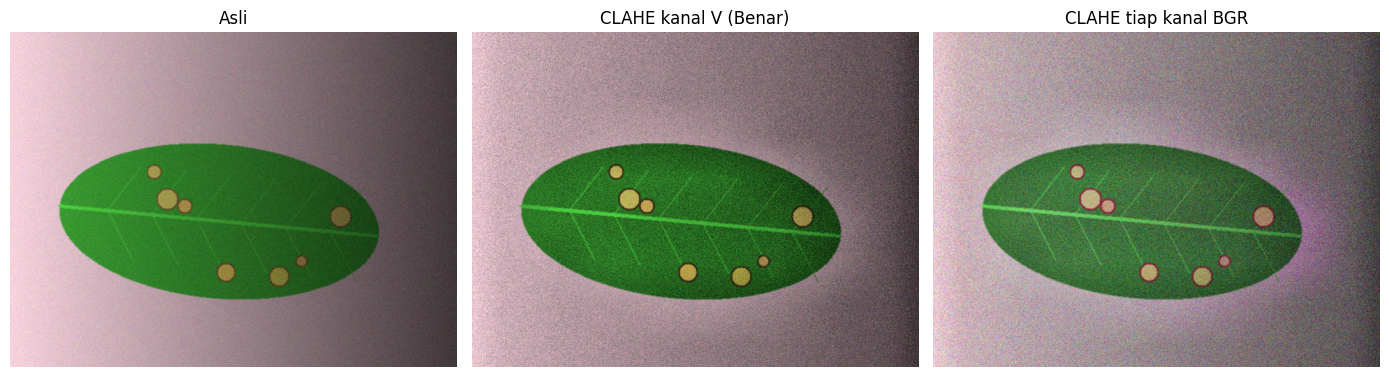

Eksperimen CLAHE selesai dan grafik disimpan ke folder hasil/


In [16]:
print("--- EKSPERIMEN PARAMETER CLAHE ---")
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        kb_val = kontras_bercak(c, md, mb)
        print(f"clip={clip} tile={tile:2d} -> KB={kb_val:.2f}")

print("\n--- CLAHE PADA CITRA WARNA ---")
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])

# Tampilkan perbandingan visual dan simpan
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V (Benar)", "CLAHE tiap kanal BGR"], baris=1, ukuran=(14, 4))
plt.savefig("../hasil/b3_perbandingan_clahe.png")
plt.show()
print("Eksperimen CLAHE selesai dan grafik disimpan ke folder hasil/")